# EDA – Mosquitos vectores (Mendeley Data + Kaggle)

# 1.Importación librerías

In [21]:
import os
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn as sk
from PIL import Image

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
SEED = 42
rng = np.random.default_rng(SEED)

# 2.Importación fuente de datos

In [2]:
# Fuentes de datos:
#  - Mendeley: https://data.mendeley.com/datasets/88s6fvgg2p/4
#  - Kaggle  : https://www.kaggle.com/datasets/pradeepisawasan/aedes-mosquitos
#  - IEEE DataPort: https://ieee-dataport.org/open-access/image-dataset-aedes-and-culex-mosquito-species
RAIZ = Path(r'D:\Vector IA\data\raw')

# (clase, fuente, ruta)  -> varias fuentes pueden aportar a la misma clase
FUENTES = [
    ('aegypti',    'kaggle',   RAIZ / 'aegypti'),
    ('albopictus', 'kaggle',   RAIZ / 'albopictus'),
    ('aegypti',    'mendeley', RAIZ / 'Original Images Mendeley' / 'Aedes Aegypti'),
    ('anopheles',  'mendeley', RAIZ / 'Original Images Mendeley' / 'Anopheles Stephensi'),
    ('culex',      'mendeley', RAIZ / 'Original Images Mendeley' / 'Culex Quinquefasciatus'),
    ('culex',      'ieee',     RAIZ / 'culex'),
    ('aedes',      'ieee',     RAIZ / 'aedes'),    # género Aedes: especie sin confirmar
]

# Imágenes aumentadas de Mendeley: NO se usan (riesgo de leakage). Solo informativo.
RUTA_AUMENTADAS = RAIZ / 'Mosquito Images Augmented'

# Confirmar que existen las carpetas
for clase, fuente, ruta in FUENTES:
    assert ruta.exists(), f'No se encontró la carpeta ({clase} / {fuente}): {ruta}'
print('Todas las carpetas encontradas en:', RAIZ)

Todas las carpetas encontradas en: D:\Vector IA\data\raw


Contamos cuántas imágenes aporta cada carpeta.

> **Nota sobre `aedes` (IEEE DataPort):** esa carpeta agrupa el **género** *Aedes*, sin separar *aegypti* de *albopictus*
> (confírmalo en la descripción del dataset). Por eso se mantiene como clase aparte, `aedes`, durante el EDA.
> **No conviene fusionarla con `aegypti` a ciegas**, porque añadiría etiquetas incorrectas. Opciones al terminar el EDA:
> (a) excluirla del entrenamiento, (b) usarla como una clase "Aedes (género)", o
> (c) pseudo-etiquetarla con un modelo ya entrenado y revisar a mano una muestra.

> **Importante:** usamos solo las **imágenes originales**. La carpeta `Mosquito Images Augmented` queda fuera:
> si se mezclaran imágenes aumentadas en train y test, la misma foto (modificada) podría quedar en ambos
> conjuntos y el F1 saldría inflado. El aumento lo haremos nosotros después de separar los datos.

In [3]:
EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

def contar_imagenes(carpeta):
    return sum(1 for f in Path(carpeta).rglob('*') if f.suffix.lower() in EXTS)

for clase, fuente, ruta in FUENTES:
    print(f'{clase:11s} | {fuente:9s} | {contar_imagenes(ruta):6d} imágenes  ({ruta.name})')

if RUTA_AUMENTADAS.exists():
    print(f'\n(Informativo) Aumentadas Mendeley, no usadas: {contar_imagenes(RUTA_AUMENTADAS)} imágenes')

aegypti     | kaggle    |   2403 imágenes  (aegypti)
albopictus  | kaggle    |   2400 imágenes  (albopictus)
aegypti     | mendeley  |     15 imágenes  (Aedes Aegypti)
anopheles   | mendeley  |      9 imágenes  (Anopheles Stephensi)
culex       | mendeley  |     20 imágenes  (Culex Quinquefasciatus)
culex       | ieee      |    594 imágenes  (culex)
aedes       | ieee      |    810 imágenes  (aedes)

(Informativo) Aumentadas Mendeley, no usadas: 2640 imágenes


## 2.1 Construcción de un DataFrame con todas las imágenes

In [4]:
registros = []
for clase, fuente, ruta in FUENTES:
    for f in ruta.rglob('*'):
        if f.suffix.lower() in EXTS:
            registros.append({'ruta': str(f),
                              'archivo': f.name,
                              'carpeta': ruta.name,
                              'clase': clase,
                              'fuente': fuente})
df = pd.DataFrame(registros)
print('Total de imágenes:', len(df))
df.head()

Total de imágenes: 6251


,ruta,archivo,carpeta,clase,fuente
0,D:\Vector IA\data\raw\aegypti\aegypti\aegypti_...,aegypti100a.jpg,aegypti,aegypti,kaggle
1,D:\Vector IA\data\raw\aegypti\aegypti\aegypti_...,aegypti100b.jpg,aegypti,aegypti,kaggle
2,D:\Vector IA\data\raw\aegypti\aegypti\aegypti_...,aegypti100c.jpg,aegypti,aegypti,kaggle
3,D:\Vector IA\data\raw\aegypti\aegypti\aegypti_...,aegypti101b.jpg,aegypti,aegypti,kaggle
4,D:\Vector IA\data\raw\aegypti\aegypti\aegypti_...,aegypti101c.jpg,aegypti,aegypti,kaggle


# 3.Preprocesado / Análisis exploratorio

## 3.1 ¿Cuántas imágenes tenemos por clase? (desbalance)

,imagenes,porcentaje_%
clase,,
aegypti,2418,38.7
albopictus,2400,38.4
aedes,810,13.0
culex,614,9.8
anopheles,9,0.1


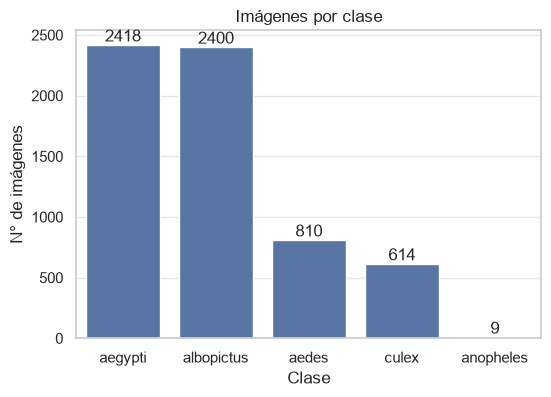

Ratio de desbalance (mayor/menor): 268.67


fuente,ieee,kaggle,mendeley
clase,,,
aedes,810,0,0
aegypti,0,2403,15
albopictus,0,2400,0
anopheles,0,0,9
culex,594,0,20


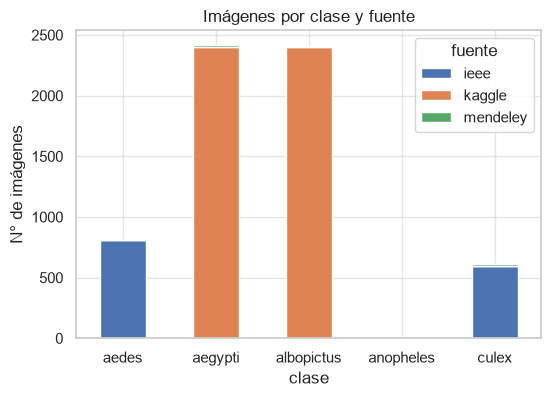

In [5]:
conteo = df['clase'].value_counts()
porcentaje = (conteo / conteo.sum() * 100).round(1)
resumen = pd.DataFrame({'imagenes': conteo, 'porcentaje_%': porcentaje})
display(resumen)

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=conteo.index, y=conteo.values, ax=ax)
for i, v in enumerate(conteo.values):
    ax.text(i, v, str(v), ha='center', va='bottom')
ax.set_title('Imágenes por clase')
ax.set_xlabel('Clase'); ax.set_ylabel('N° de imágenes')
plt.show()

print(f'Ratio de desbalance (mayor/menor): {conteo.max() / conteo.min():.2f}')

# ¿De qué fuente viene cada clase?
tabla_fuente = pd.crosstab(df['clase'], df['fuente'])
display(tabla_fuente)
tabla_fuente.plot(kind='bar', stacked=True, figsize=(6, 4), rot=0)
plt.title('Imágenes por clase y fuente'); plt.ylabel('N° de imágenes')
plt.show()

**Class weights** (pesos por clase): se calculan con la fórmula `n_total / (n_clases * n_clase)`.
Las clases con menos imágenes pesan más durante el entrenamiento. Los dejamos calculados para usarlos en `model.fit(class_weight=...)`.

In [7]:
from sklearn.utils.class_weight import compute_class_weight

clases_ordenadas = sorted(df['clase'].unique())   # mismo orden alfabético que flow_from_directory
pesos = compute_class_weight('balanced', classes=np.array(clases_ordenadas), y=df['clase'])
class_weights = {i: float(w) for i, w in enumerate(pesos)}

print('Índices de clase:', {c: i for i, c in enumerate(clases_ordenadas)})
print('class_weights   :', {k: round(v, 3) for k, v in class_weights.items()})

Índices de clase: {'aedes': 0, 'aegypti': 1, 'albopictus': 2, 'anopheles': 3, 'culex': 4}
class_weights   : {0: 1.543, 1: 0.517, 2: 0.521, 3: 138.911, 4: 2.036}


## 3.2 Visualización de imágenes

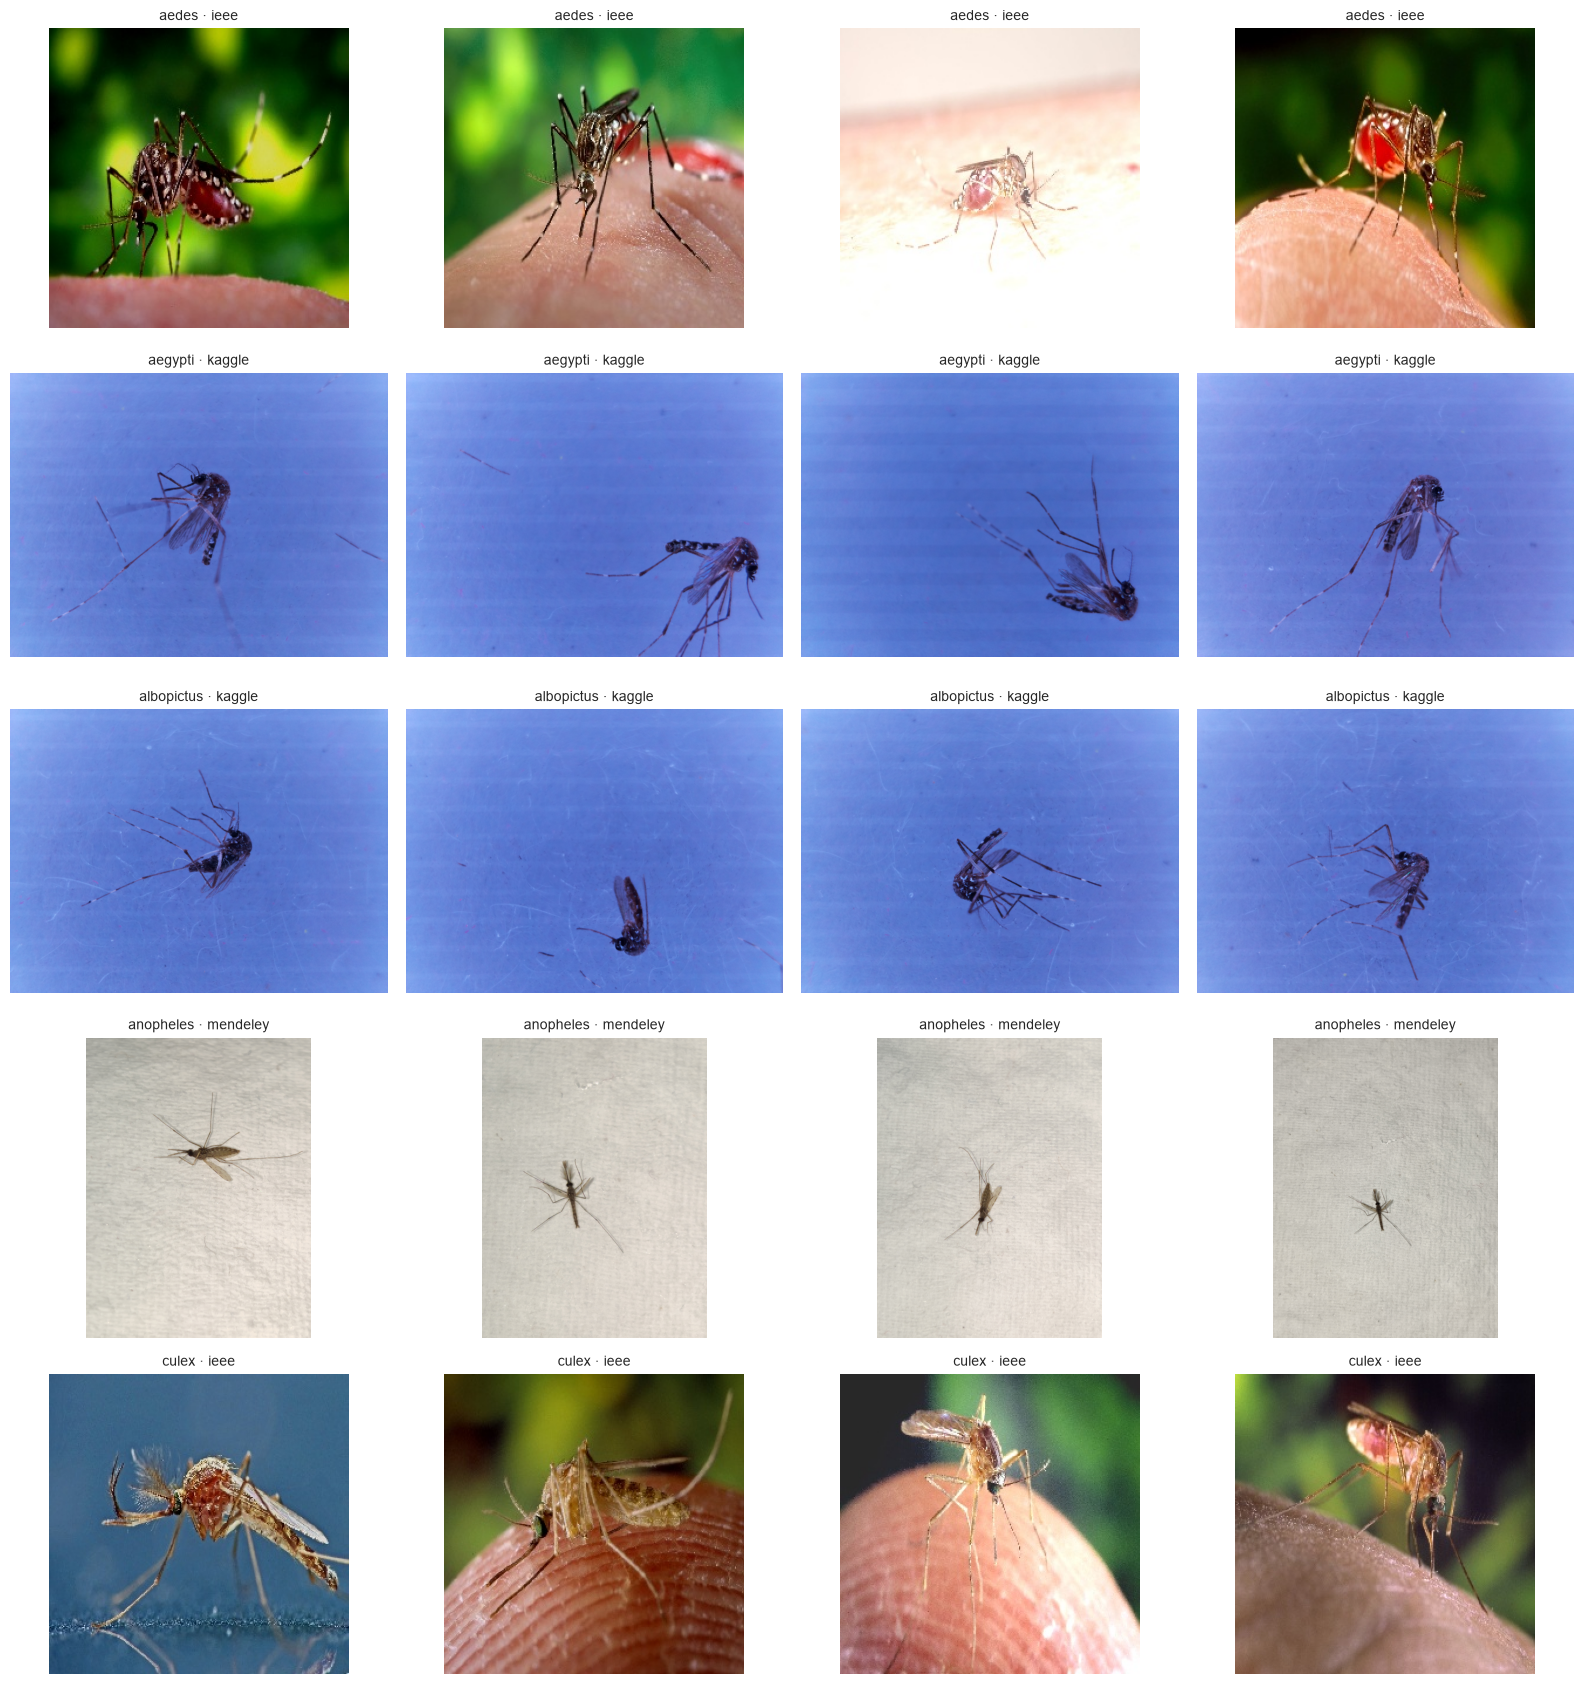

In [8]:
N_POR_CLASE = 4
clases = sorted(df['clase'].unique())
fig, axes = plt.subplots(len(clases), N_POR_CLASE, figsize=(4 * N_POR_CLASE, 3.4 * len(clases)))
axes = np.atleast_2d(axes)

for i, c in enumerate(clases):
    muestra = df[df['clase'] == c].sample(N_POR_CLASE, random_state=SEED)
    for j, (ruta, fuente) in enumerate(zip(muestra['ruta'], muestra['fuente'])):
        axes[i, j].imshow(Image.open(ruta))
        axes[i, j].axis('off')
        axes[i, j].set_title(f'{c} · {fuente}', fontsize=10)
plt.tight_layout()
plt.show()

Ejemplo individual: cargar una imagen con `imread` y ver su `shape`.

shape (alto, ancho, canales): (2464, 3280, 3)


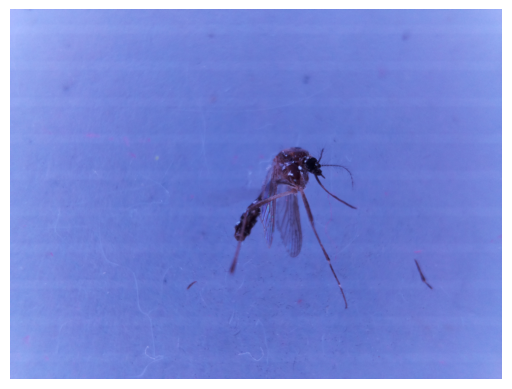

In [9]:
from matplotlib.image import imread

ruta_ejemplo = df[df['clase'] == 'aegypti'].iloc[0]['ruta']
imagen_ejemplo = imread(ruta_ejemplo)
plt.imshow(imagen_ejemplo)
plt.axis('off')
print('shape (alto, ancho, canales):', imagen_ejemplo.shape)

## 3.3 Calcular dimensiones, formatos y tamaño de archivo

Abrimos cada imagen con PIL (solo lee la cabecera, es rápido) para obtener ancho, alto, modo de color y formato.
Si alguna imagen está corrupta, queda marcada en la columna `error`.

In [10]:
def leer_metadatos(ruta):
    try:
        with Image.open(ruta) as im:
            ancho, alto = im.size
            return dict(ancho=ancho, alto=alto, modo=im.mode, formato=im.format,
                        kb=os.path.getsize(ruta) / 1024, error=False)
    except Exception:
        return dict(ancho=np.nan, alto=np.nan, modo=None, formato=None, kb=np.nan, error=True)

meta = pd.DataFrame([leer_metadatos(r) for r in df['ruta']])
df = pd.concat([df.reset_index(drop=True), meta], axis=1)
df['aspecto'] = df['ancho'] / df['alto']
df_ok = df[~df['error']].copy()
print('Imágenes corruptas:', int(df['error'].sum()))
df_ok[['ancho', 'alto', 'aspecto', 'kb']].describe().round(2)

Imágenes corruptas: 0


,ancho,alto,aspecto,kb
count,6251.00,6251.00,6251.00,6251.00
mean,2598.49,1978.44,1.25,3205.21
std,1261.27,935.54,0.14,1718.02
min,256.00,256.00,0.75,8.01
25%,3280.00,2464.00,1.33,4080.18
50%,3280.00,2464.00,1.33,4129.67
75%,3280.00,2464.00,1.33,4153.60
max,3280.00,4000.00,1.33,4226.10


In [11]:
df_ok.groupby('clase')[['ancho', 'alto', 'kb']].agg(['min', 'mean', 'max']).round(0)

ancho                alto                    kb                
             min    mean   max   min    mean   max     min    mean     max
clase                                                                     
aedes        256   256.0   256   256   256.0   256    10.0    22.0    39.0
aegypti     1944  3277.0  3280  2464  2472.0  4000  2029.0  4113.0  4214.0
albopictus  3280  3280.0  3280  2464  2464.0  2464  4070.0  4155.0  4226.0
anopheles   3000  3000.0  3000  4000  4000.0  4000  2037.0  2386.0  3745.0
culex        256   345.0  3000   256   378.0  4000     8.0   127.0  3361.0

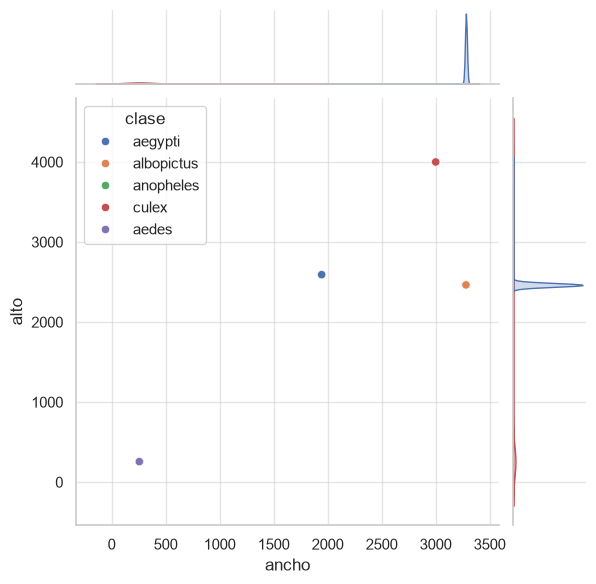

In [12]:
sns.jointplot(data=df_ok, x='ancho', y='alto', hue='clase', height=6)
plt.show()

**Por fuente:** si Kaggle y Mendeley tienen tamaños muy distintos, la resolución por sí sola delataría la fuente.

ancho                alto                    kb                
           min    mean   max   min    mean   max     min    mean     max
fuente                                                                  
ieee       256   256.0   256   256   256.0   256     8.0    22.0    40.0
kaggle    3280  3280.0  3280  2464  2464.0  2464  4006.0  4140.0  4226.0
mendeley  1944  2952.0  3000  2592  3936.0  4000  2029.0  2716.0  3745.0

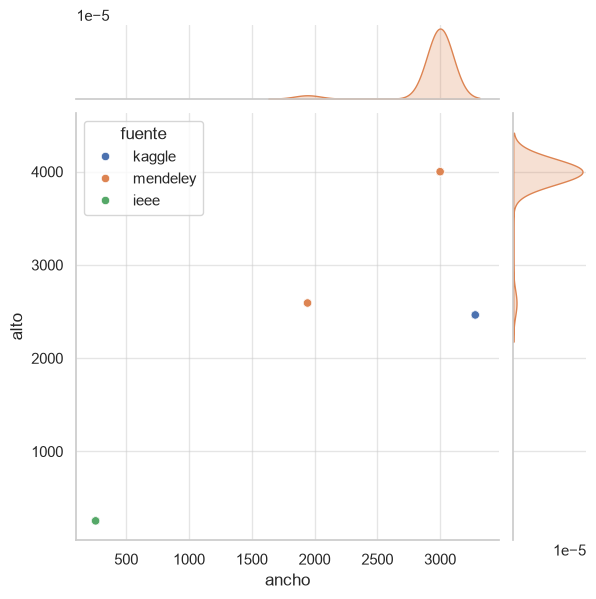

In [13]:
display(df_ok.groupby('fuente')[['ancho', 'alto', 'kb']].agg(['min', 'mean', 'max']).round(0))
sns.jointplot(data=df_ok, x='ancho', y='alto', hue='fuente', height=6)
plt.show()

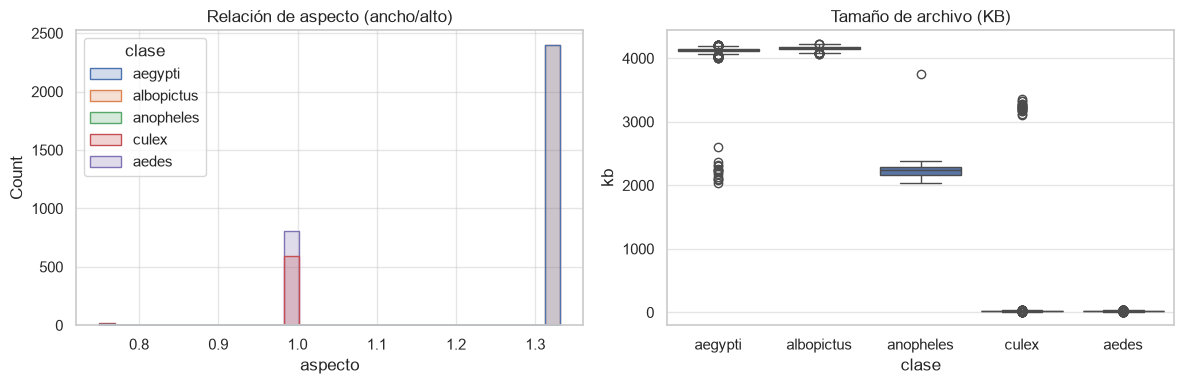

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df_ok, x='aspecto', hue='clase', bins=30, ax=axes[0], element='step')
axes[0].set_title('Relación de aspecto (ancho/alto)')
sns.boxplot(data=df_ok, x='clase', y='kb', ax=axes[1])
axes[1].set_title('Tamaño de archivo (KB)')
plt.tight_layout()
plt.show()

In [15]:
# Dimensiones promedio (como en el notebook de flores) y tamaño de entrada elegido
print('Ancho promedio:', round(df_ok['ancho'].mean()))
print('Alto promedio :', round(df_ok['alto'].mean()))

IMG_SIZE = (128, 128)            # (alto, ancho) -> el que sugiere el enunciado
image_shape = IMG_SIZE + (3,)
print('image_shape   :', image_shape)

Ancho promedio: 2598
Alto promedio : 1978
image_shape   : (128, 128, 3)


> Las fotos de celular suelen ser mucho más grandes que 128×128 y no siempre cuadradas.
> Al redimensionar a 128×128 se **deforma** la relación de aspecto. Es aceptable para empezar, pero conviene
> revisar que el mosquito siga siendo reconocible. Además, algunas fotos pueden venir rotadas por metadatos EXIF:
> al cargarlas para entrenar se recomienda aplicar `ImageOps.exif_transpose`.

## 3.4 Calidad de los datos: modos de color y formatos

In [16]:
print('Modo de color:')
print(df_ok['modo'].value_counts(), '\n')
print('Formato:')
print(df_ok['formato'].value_counts())

Modo de color:
modo
RGB    6251
Name: count, dtype: int64 

Formato:
formato
JPEG    6251
Name: count, dtype: int64


Si aparecen imágenes en escala de grises (`L`) o con transparencia (`RGBA`), hay que convertirlas a `RGB`
(`color_mode='rgb'` en el generador lo hace automáticamente).

## 3.5 Duplicados exactos

In [17]:
def md5_archivo(ruta):
    h = hashlib.md5()
    with open(ruta, 'rb') as f:
        for bloque in iter(lambda: f.read(1 << 20), b''):
            h.update(bloque)
    return h.hexdigest()

df_ok['md5'] = df_ok['ruta'].map(md5_archivo)
dup = df_ok[df_ok.duplicated('md5', keep=False)]
print('Imágenes involucradas en duplicados exactos:', len(dup))

# ¿Hay un mismo archivo etiquetado con clases distintas? (sería un error de etiquetado)
cruzados = dup.groupby('md5')['clase'].nunique()
print('Grupos duplicados con clases distintas:', int((cruzados > 1).sum()))
print('Grupos duplicados presentes en ambas fuentes:', int((dup.groupby('md5')['fuente'].nunique() > 1).sum()))
dup.groupby('clase').size()

Imágenes involucradas en duplicados exactos: 110
Grupos duplicados con clases distintas: 0
Grupos duplicados presentes en ambas fuentes: 0


clase
aedes      60
aegypti     6
culex      44
dtype: int64

## 3.6 Análisis de color y brillo por clase

Para no leer miles de imágenes grandes completas, usamos una muestra y las reducimos a 64×64 (con `draft`, que acelera la lectura de JPEG).

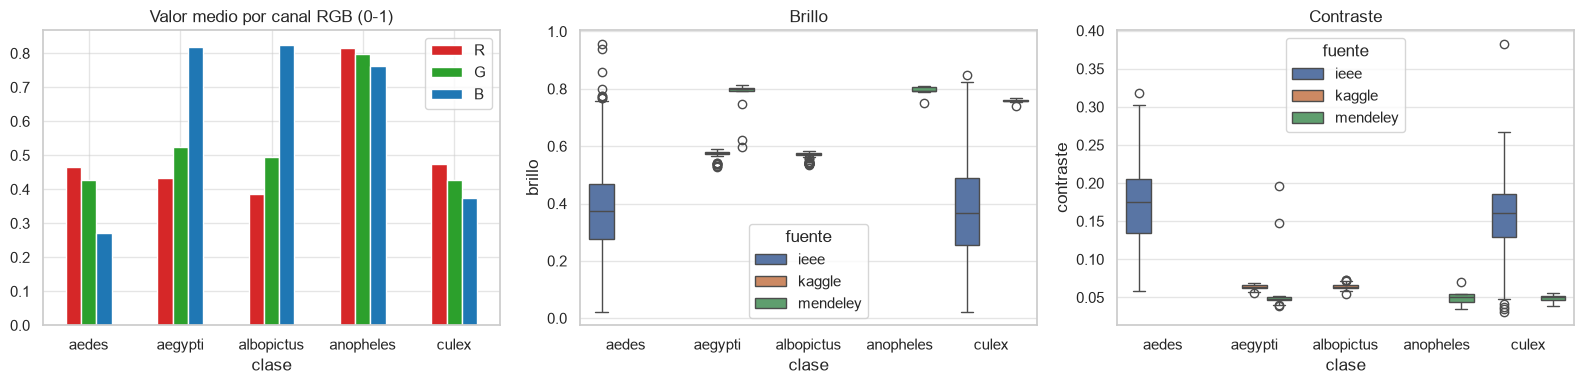

In [18]:
def estadisticas_color(ruta, lado=64):
    with Image.open(ruta) as im:
        im.draft('RGB', (lado * 2, lado * 2))
        arr = np.asarray(im.convert('RGB').resize((lado, lado)), dtype=np.float32) / 255
    gris = arr.mean(axis=2)
    return dict(R=arr[..., 0].mean(), G=arr[..., 1].mean(), B=arr[..., 2].mean(),
                brillo=gris.mean(), contraste=gris.std())

N_MUESTRA = 150   # por clase y fuente
muestra = pd.concat([g.sample(min(len(g), N_MUESTRA), random_state=SEED)
                     for _, g in df_ok.groupby(['clase', 'fuente'])])
color = pd.DataFrame([estadisticas_color(r) for r in muestra['ruta']], index=muestra.index)
color['clase'] = muestra['clase']
color['fuente'] = muestra['fuente']

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
color.groupby('clase')[['R', 'G', 'B']].mean().plot(kind='bar', ax=axes[0], color=['tab:red', 'tab:green', 'tab:blue'])
axes[0].set_title('Valor medio por canal RGB (0-1)'); axes[0].tick_params(axis='x', rotation=0)
sns.boxplot(data=color, x='clase', y='brillo', hue='fuente', ax=axes[1]); axes[1].set_title('Brillo')
sns.boxplot(data=color, x='clase', y='contraste', hue='fuente', ax=axes[2]); axes[2].set_title('Contraste')
plt.tight_layout()
plt.show()

Si una clase tiene un brillo o color de fondo muy distinto al resto, la CNN podría aprender el **fondo / la iluminación**
en lugar del mosquito (sesgo del dataset). Compara especialmente *aegypti* de Kaggle vs Mendeley: si difieren mucho en brillo o color,
la fuente es una pista fácil para la red. Conviene revisar esto al interpretar los resultados (por ejemplo con Grad-CAM).

## 3.7 Casi-duplicados y riesgo de *data leakage*

Según los autores, las fotos provienen de pocos especímenes (decenas), fotografiados muchas veces.
Entonces fotos casi idénticas pueden caer en train y en test, y el modelo "memoriza" el espécimen en lugar de
aprender la especie. Usamos un *average hash* (8×8) y contamos las imágenes que tienen un vecino casi idéntico.

In [19]:
def ahash(ruta, lado=8):
    with Image.open(ruta) as im:
        im.draft('L', (lado * 8, lado * 8))
        g = np.asarray(im.convert('L').resize((lado, lado)), dtype=np.float32)
    return (g > g.mean()).flatten()

H = np.stack([ahash(r) for r in df_ok['ruta']]).astype(np.float32)   # (n, 64)
n = len(H)
clases_cod = pd.factorize(df_ok['clase'])[0]
fuentes_cod = pd.factorize(df_ok['fuente'])[0]

UMBRAL = 5                                   # <= 5 bits distintos de 64 = casi idénticas
TAM_BLOQUE = 1000                            # por bloques para no agotar la memoria
tiene_vecino = np.zeros(n, dtype=bool)
cruzado = np.zeros(n, dtype=bool)            # vecino de OTRA clase
cruzado_fuente = np.zeros(n, dtype=bool)     # vecino de OTRA fuente

for ini in range(0, n, TAM_BLOQUE):
    fin = min(ini + TAM_BLOQUE, n)
    dist = H[ini:fin] @ (1 - H).T + (1 - H[ini:fin]) @ H.T      # distancia de Hamming
    dist[np.arange(fin - ini), np.arange(ini, fin)] = 64         # ignorar la propia imagen
    vec = dist <= UMBRAL
    tiene_vecino[ini:fin] = vec.any(axis=1)
    cruzado[ini:fin] = (vec & (clases_cod[ini:fin, None] != clases_cod[None, :])).any(axis=1)
    cruzado_fuente[ini:fin] = (vec & (fuentes_cod[ini:fin, None] != fuentes_cod[None, :])).any(axis=1)

print(f'Imágenes con al menos un casi-duplicado: {tiene_vecino.mean():.1%}')
print('\nPor clase y fuente:')
print(pd.Series(tiene_vecino, index=df_ok.index).groupby([df_ok['clase'], df_ok['fuente']]).mean().round(3))
print(f'\nImágenes con casi-duplicado de OTRA clase : {int(cruzado.sum())}')
print(f'Imágenes con casi-duplicado de OTRA fuente: {int(cruzado_fuente.sum())}')

Imágenes con al menos un casi-duplicado: 97.3%

Por clase y fuente:
clase       fuente  
aedes       ieee        0.884
aegypti     kaggle      1.000
            mendeley    0.600
albopictus  kaggle      1.000
anopheles   mendeley    0.889
culex       ieee        0.896
            mendeley    0.850
dtype: float64

Imágenes con casi-duplicado de OTRA clase : 5096
Imágenes con casi-duplicado de OTRA fuente: 92


Si el porcentaje es alto, el F1 de un split aleatorio será optimista. Mitigaciones: agrupar imágenes parecidas
(clustering por hash/embeddings) y repartir **grupos completos** entre train/val/test, y reportar esta limitación.

## 3.8 Manipulación de imágenes (Data Augmentation)

Igual que en el notebook de flores, usamos `ImageDataGenerator`. Aquí solo **previsualizamos** las transformaciones
sobre una imagen de cada clase. Ojo: el volteo horizontal y rotaciones suaves son seguros para mosquitos;
evitar transformaciones de color agresivas que alteren los patrones de las patas/alas.

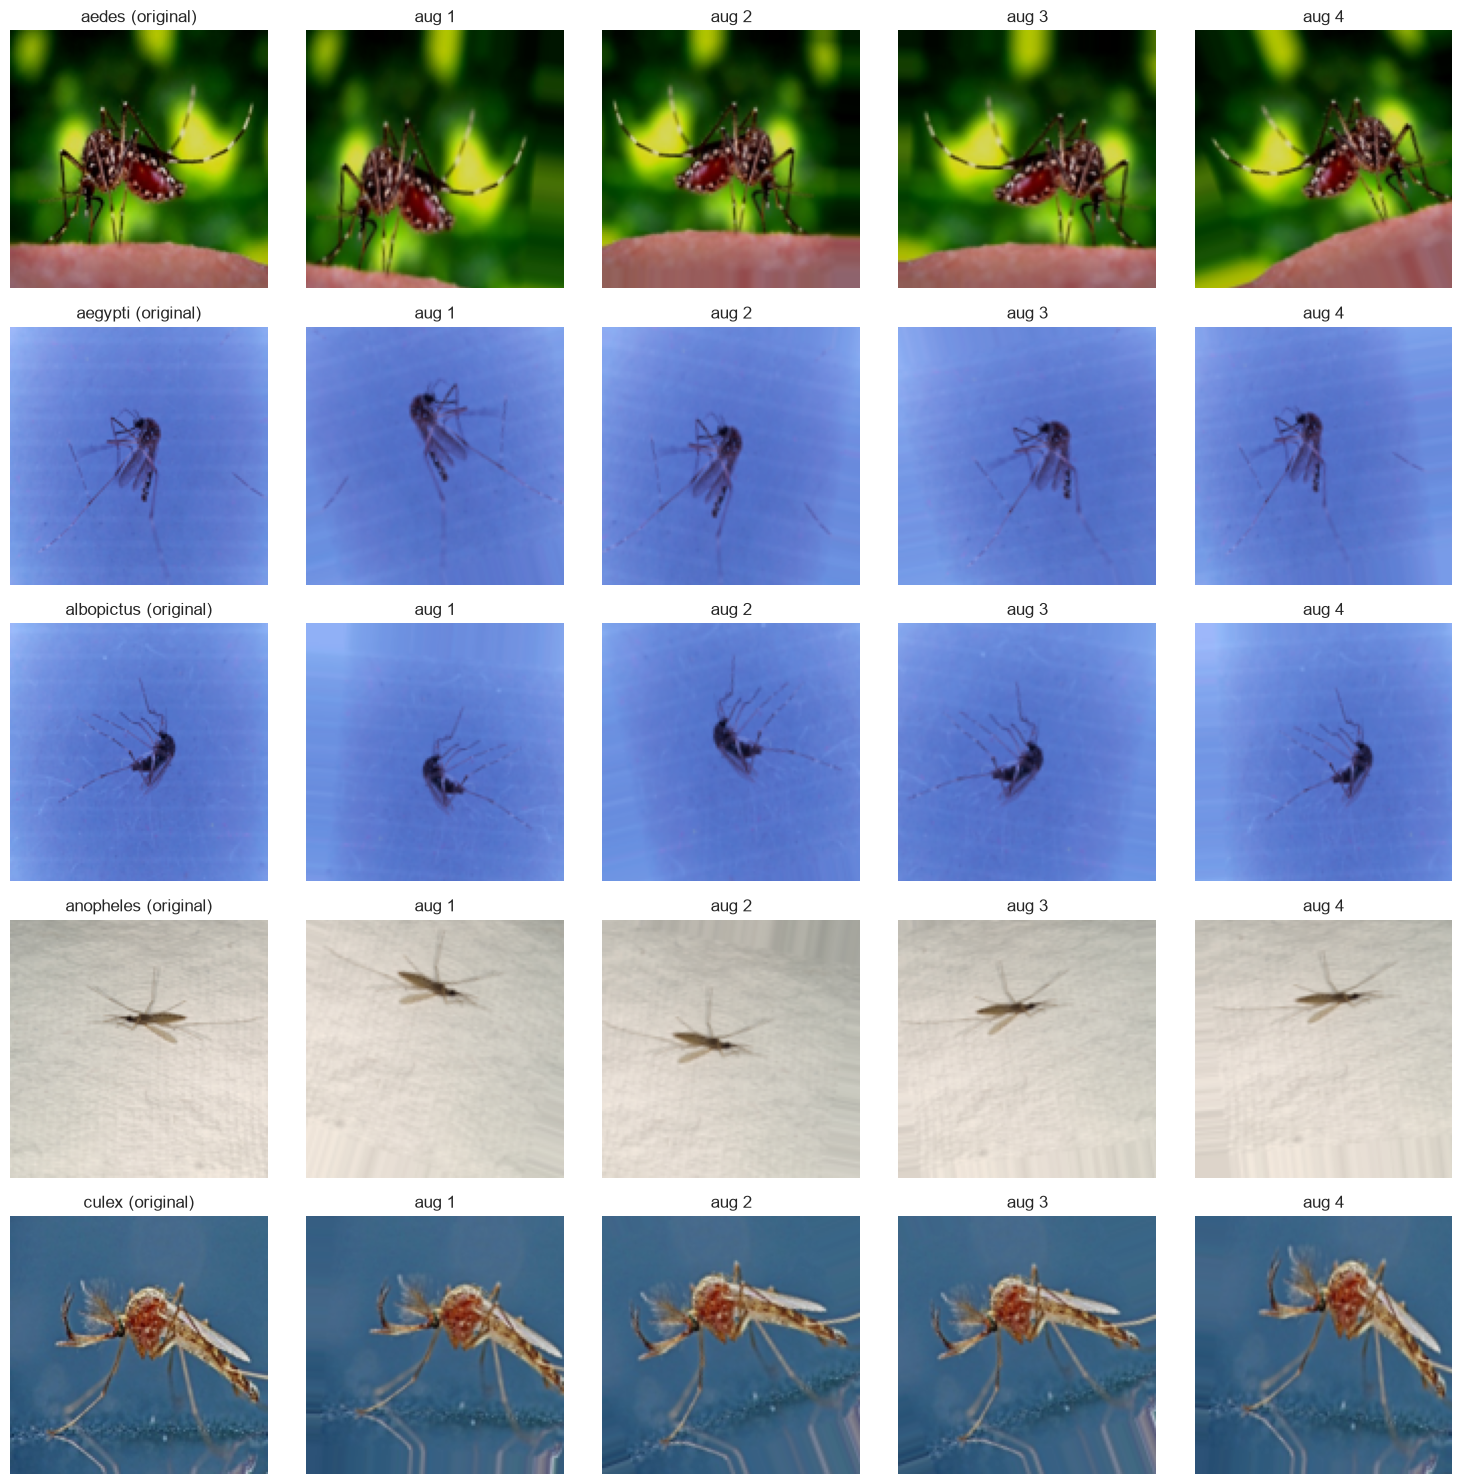

In [20]:
try:
    from tensorflow.keras.preprocessing.image import ImageDataGenerator
except ImportError:
    raise SystemExit('Instala tensorflow: pip install tensorflow')

image_gen = ImageDataGenerator(rotation_range=20,
                               width_shift_range=0.10,
                               height_shift_range=0.10,
                               rescale=1/255,
                               shear_range=0.1,
                               zoom_range=0.1,
                               horizontal_flip=True,
                               fill_mode='nearest')

N_AUG = 4
clases = sorted(df_ok['clase'].unique())
fig, axes = plt.subplots(len(clases), N_AUG + 1, figsize=(3 * (N_AUG + 1), 3 * len(clases)))
axes = np.atleast_2d(axes)

for i, c in enumerate(clases):
    ruta = df_ok[df_ok['clase'] == c].sample(1, random_state=SEED)['ruta'].iloc[0]
    arr = np.asarray(Image.open(ruta).convert('RGB').resize(IMG_SIZE[::-1]), dtype=np.float32)
    axes[i, 0].imshow(arr / 255); axes[i, 0].set_title(f'{c} (original)'); axes[i, 0].axis('off')
    for j in range(1, N_AUG + 1):
        aug = image_gen.standardize(image_gen.random_transform(arr.copy()))
        axes[i, j].imshow(np.clip(aug, 0, 1)); axes[i, j].set_title(f'aug {j}'); axes[i, j].axis('off')
plt.tight_layout()
plt.show()